## Principal Component Analysis(dimensionality reduction technique used in machine learning to reduce the number of features (columns) in a dataset while preserving as much important information as possible.)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# -----------------------------
# Load dataset from GitHub raw
# -----------------------------
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(url)

df.head()


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
# -----------------------------
# Split features and target
# -----------------------------
X = df.drop("species", axis=1)

# convert categorical target to numeric
y = df["species"].astype("category").cat.codes

# -----------------------------
# Standardize features
# -----------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# -----------------------------
# Apply PCA
# -----------------------------
pca = PCA()
#PCA() creates a PCA object.
#It prepares the PCA algorithm to perform dimensionality reduction.
#Since we didn't specify the number of components, it initially keeps all possible components.
X_pca = pca.fit_transform(X_scaled)
#This line performs three tasks:
#1. Fit: Learns the principal components from X_scaled.
#2. Transform: Converts the original features into new principal components.
#3. Store: Saves the transformed data in X_pca.


In [3]:
# -----------------------------
# Variance analysis
# -----------------------------
explained_variance = pca.explained_variance_ratio_
#pca.explained_variance_ratio_ tells us how much information (variance) each principal component preserves from the original data.
#The values are represented as proportions.
cumulative_variance = np.cumsum(explained_variance)
#It adds each value to the sum of all previous values.

# Format output
print("\nExplained variance ratio:")
print([f"{x:.2f}" for x in explained_variance])

print("\nCumulative explained variance:")
print([f"{x:.2f}" for x in cumulative_variance])

# -----------------------------
# Highlight key insight (colored)
# -----------------------------
print("\n\033[1;32mTwo principal components explain ~96% of the variance.\033[0m")
print("\033[1;34mSo we can reduce 4D data → 2D with minimal information loss.\033[0m")


Explained variance ratio:
['0.73', '0.23', '0.04', '0.01']

Cumulative explained variance:
['0.73', '0.96', '0.99', '1.00']

Two principal components explain ~96% of the variance.
So we can reduce 4D data → 2D with minimal information loss.


In [ ]:
# -----------------------------Cumulative variance in PCA means:The total amount of information (variance) explained by the first few principal components together.
# Plot cumulative variance
# -----------------------------
plt.figure()
plt.plot(range(1, len(cumulative_variance) + 1),
         cumulative_variance,
         marker='o')

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance (Iris from GitHub)")
plt.grid(True)
plt.ylim(0, 1.05)
plt.show()


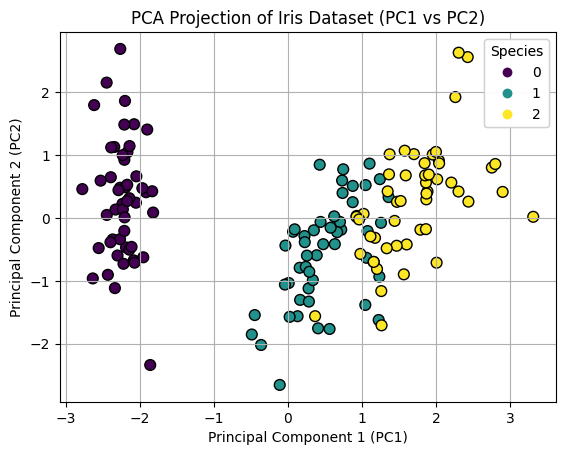

In [4]:
# -----------------------------PCA takes the original features → creates new features called PC1, PC2, PC3, PC4 → then this graph shows the data using only PC1 and PC2
# Plot PC1 vs PC2
# -----------------------------
plt.figure()

scatter = plt.scatter(
    X_pca[:, 0],  # first principal component -> 1st new feature
    X_pca[:, 1],
    c=y, #c=y gives different colors to the different species.
    cmap="viridis",
    edgecolor="k",
    s=60
)

plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.title("PCA Projection of Iris Dataset (PC1 vs PC2)")
plt.grid(True)

# legend
legend1 = plt.legend(
    handles=scatter.legend_elements()[0],
    labels=list(y.unique()),
    title="Species"
)

plt.gca().add_artist(legend1)

plt.show()